# BÁO CÁO PHẦN 1 - BÀI 2 (TRANG 15-17): TITANIC DATASET
## CÂU 5: Thống kê số người đi cùng (relatives, not_alone) và khảo sát sự liên quan với sống sót
- Tạo thuộc tính `relatives` = `sibsp` + `parch`
- Tạo thuộc tính `not_alone` (1: đi một mình, 0: có người thân đi cùng)
- Khảo sát mối liên quan bằng biểu đồ catplot


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- THỐNG KÊ SỐ NGƯỜI ĐI MỘT MÌNH VÀ ĐI CÙNG NGƯỜI THÂN ---
not_alone
1    790
0    519
Name: count, dtype: int64
• Số người đi một mình (not_alone = 1): 790 người.
• Số người đi cùng người thân (not_alone = 0): 519 người.


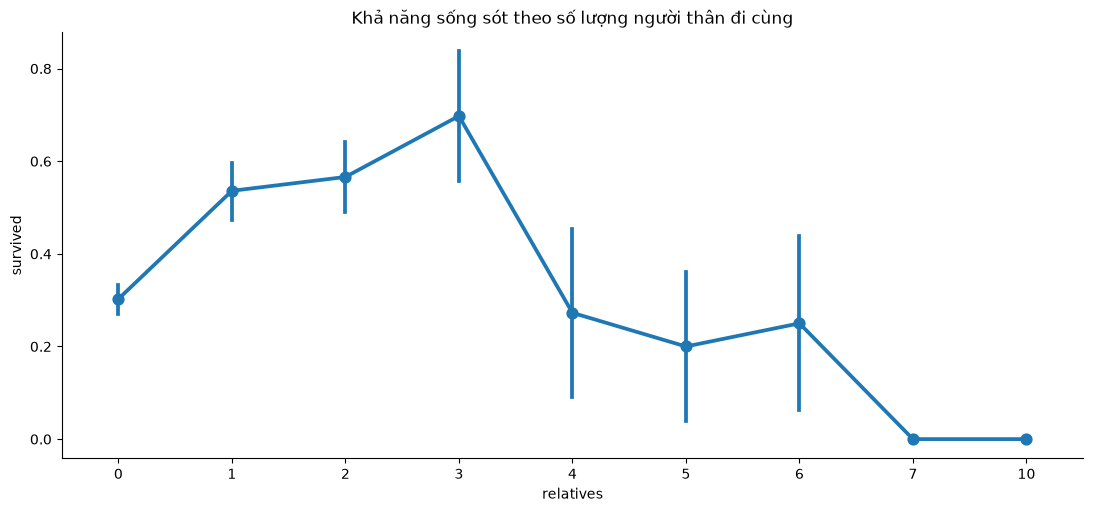

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename


path = get_data_path('titanic.csv')
with open(path) as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

for dataset in [df]:
    dataset['relatives'] = dataset['sibsp'] + dataset['parch']
    dataset.loc[dataset['relatives'] > 0, 'not_alone'] = 0
    dataset.loc[dataset['relatives'] == 0, 'not_alone'] = 1
    dataset['not_alone'] = dataset['not_alone'].astype(int)

counts = df['not_alone'].value_counts()
print("--- THỐNG KÊ SỐ NGƯỜI ĐI MỘT MÌNH VÀ ĐI CÙNG NGƯỜI THÂN ---")
print(counts)
print(f"• Số người đi một mình (not_alone = 1): {counts[1]} người.")
print(f"• Số người đi cùng người thân (not_alone = 0): {counts[0]} người.")

# Vẽ biểu đồ mối quan hệ giữa relatives và survived
axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.2, kind='point')
plt.title("Khả năng sống sót theo số lượng người thân đi cùng")
plt.show()


### Nhận xét Câu 5:
- Số người đi một mình là 790 người; số người đi cùng người thân là 519 người.
- Những người có từ 1 đến 3 người thân đi cùng có tỷ lệ sống sót cao nhất (từ 53% đến gần 70%).
- Những người đi một mình có tỷ lệ sống sót chỉ khoảng 30%.
- Những người đi cùng gia đình quá đông (từ 7 đến 10 người) có tỷ lệ sống sót thấp nhất (gần 0%), có thể do khó khăn trong việc tập hợp và tìm thuyền cứu sinh cùng nhau.
